In [ ]:
# ═════════════════════════════════════════════════════════════════════════════
# FORM A — EDA EXECUTIVE SUMMARY
# Run this cell after all 7 EDA cells have been executed
# ═════════════════════════════════════════════════════════════════════════════

summary = """
╔══════════════════════════════════════════════════════════════════════════════╗
║          FORM A QUESTION BANK — EDA KEY FINDINGS SUMMARY                   ║
╚══════════════════════════════════════════════════════════════════════════════╝

DATASET
  • 398 raw responses · 34 respondents · 4 scenarios · 100 selected (25 each)
  • Average response length: ~12 words across all types

──────────────────────────────────────────────────────────────────────────────
FINDING 1 — LENGTH SWEET SPOT  (Cell 2)
  • Medium responses (11–25 words) had 39% selection rate — highest of any category
  • Fragments (1–4 words): 6% selection · Very Long (50+): 0% selection
  • Selection is not about writing more — it is about writing at the right precision

FINDING 2 — SELECTION IS TYPE-NEUTRAL, RESPONDENT-DRIVEN  (Cell 3)
  • All 4 question types selected at ~25% — by design, equal quality was achievable
  • Per-respondent rates ranged from 0% to 100% — a small group carried the dataset
  • Having a question mark doubles selection rate (42% vs 19%)

FINDING 3 — 13 ENGAGED RESPONDENTS AUTHORED THE QUESTION BANK  (Cell 4)
  • Engaged group (13/34): avg 16.1 words, 4.5% fragments, 52.6% selection rate
  • Disengaged group (6/34): avg 3.1 words, 81.9% fragments, 2.8% selection rate
  • Moderate group (15/34): majority of participants, contributed ~9.5% selection rate

FINDING 4 — MOST PARTICIPANTS THINK IN ACTIONS, NOT QUESTIONS  (Cell 5)
  • Majority of first words are action/statement form, not question words
  • Hypothetical scenario generated most question-form thinking (~68%)
  • Factual generated the least despite being the "factual question" type
  • Each scenario produced a distinct vocabulary fingerprint (confirmed semantic diversity)

FINDING 5 — FOUR TYPES OVERLAP SEMANTICALLY  (Cell 6)
  • t-SNE shows no clean cluster separation — shared survival concerns cut across types
  • Advisory and Hypothetical show most separation; Factual and Procedural overlap heavily
  • Selected questions (red) are spread across the entire embedding space
    → confirms the final bank has broad semantic coverage, not a narrow cluster

FINDING 6 — 80% OF SELECTED RESPONSES NEEDED MEANINGFUL REWRITING  (Cell 7)
  • Mean raw→cleaned similarity: 0.79
  • Only 20% minimal edits (≥0.90) · 45% moderate · 35% heavy (<0.75)
  • Advisory least rewritten (0.83) · Factual most rewritten (0.77)
  • The final 100 questions preserve participant intent but are curator-refined

──────────────────────────────────────────────────────────────────────────────
OVERALL TAKEAWAY
  The question bank is ecologically valid — it reflects how real people think
  during disaster scenarios. Most think in actions, not questions. A minority
  of engaged respondents produced the majority of usable content. The curation
  process was substantial: it converted fragments, typos, and embedded tips
  into clean, evaluable questions while preserving the original intent.
  The final 100-item bank has broad semantic coverage confirmed by embedding
  analysis — making it a sound empirical foundation for LLM consistency testing.
══════════════════════════════════════════════════════════════════════════════
"""

print(summary)


╔══════════════════════════════════════════════════════════════════════════════╗
║          FORM A QUESTION BANK — EDA KEY FINDINGS SUMMARY                   ║
╚══════════════════════════════════════════════════════════════════════════════╝

DATASET
  • 398 raw responses · 34 respondents · 4 scenarios · 100 selected (25 each)
  • Average response length: ~12 words across all types

──────────────────────────────────────────────────────────────────────────────
FINDING 1 — LENGTH SWEET SPOT  (Cell 2)
  • Medium responses (11–25 words) had 39% selection rate — highest of any category
  • Fragments (1–4 words): 6% selection · Very Long (50+): 0% selection
  • Selection is not about writing more — it is about writing at the right precision

FINDING 2 — SELECTION IS TYPE-NEUTRAL, RESPONDENT-DRIVEN  (Cell 3)
  • All 4 question types selected at ~25% — by design, equal quality was achievable
  • Per-respondent rates ranged from 0% to 100% — a small group carried the dataset
  • Having a quest

In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
# CELL 1 — Load Form A data from all 4 sheets
# ─────────────────────────────────────────────────────────────────────────────
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from IPython.display import display
import warnings
warnings.filterwarnings("ignore")

XLSX_PATH = "/content/Question_Bank_Curation.xlsx"

SHEET_INFO = {
    "FACTUAL":      "Typhoon Haiyan 2013",
    "PROCEDURAL":   "European Floods 2021",
    "ADVISORY":     "Cape Town Day Zero 2018",
    "HYPOTHETICAL": "USGS Seismic Risk",
}
TYPE_COLORS = {
    "FACTUAL":      "#1C7293",
    "PROCEDURAL":   "#E76F51",
    "ADVISORY":     "#2A9D8F",
    "HYPOTHETICAL": "#E9C46A",
}

frames = []
for sheet, scenario in SHEET_INFO.items():
    df = pd.read_excel(XLSX_PATH, sheet_name=sheet, header=1)   # row 1 = header
    df.columns = ["#", "Respondent", "RawResponse", "Slot", "CleanedQuestion", "Selected", "WhySelected"]
    df = df.dropna(subset=["RawResponse"]).copy()
    df["Type"]     = sheet
    df["Scenario"] = scenario
    df["Selected"] = df["Selected"].fillna("NO").str.strip().str.upper() == "YES"
    frames.append(df)

df = pd.concat(frames, ignore_index=True)

# Add text features
df["RawResponse"] = df["RawResponse"].astype(str).str.strip()
df["word_count"]  = df["RawResponse"].str.split().str.len()
df["char_count"]  = df["RawResponse"].str.len()
df["has_question_mark"] = df["RawResponse"].str.contains(r"\?")
df["starts_with_q_word"] = df["RawResponse"].str.match(
    r"^(what|how|where|when|why|who|which|is|are|can|should|will|do|does)\b",
    case=False
)
df["SlotNum"] = df["Slot"].str.extract(r"Q(\d)").astype(float)

# Length categories
bins   = [0, 4, 10, 25, 50, 999]
labels = ["Fragment\n(1–4w)", "Short\n(5–10w)", "Medium\n(11–25w)", "Long\n(26–50w)", "Very Long\n(50+w)"]
df["LengthCat"] = pd.cut(df["word_count"], bins=bins, labels=labels)

print(f" Loaded {len(df):,} responses from {df['Respondent'].nunique()} respondents")
print(df.groupby("Type")[["word_count","Selected"]].agg(
    count=("word_count","count"), avg_words=("word_count","mean"), selected=("Selected","sum")
).round(1))

 Loaded 398 responses from 34 respondents
              count  avg_words  selected
Type                                    
ADVISORY         96       12.2        25
FACTUAL         102       11.3        25
HYPOTHETICAL     99       12.6        25
PROCEDURAL      101       12.5        25


398 raw responses, 34 respondents, perfectly balanced at 25 selected per question type. Factual responses are shortest (~ 11w) because people name things; Hypothetical and Procedural are longer (~12.5w) because scenario-reasoning requires more words.

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype   
---  ------              --------------  -----   
 0   #                   398 non-null    object  
 1   Respondent          398 non-null    object  
 2   RawResponse         398 non-null    object  
 3   Slot                398 non-null    object  
 4   CleanedQuestion     100 non-null    object  
 5   Selected            398 non-null    bool    
 6   WhySelected         100 non-null    object  
 7   Type                398 non-null    object  
 8   Scenario            398 non-null    object  
 9   word_count          398 non-null    int64   
 10  char_count          398 non-null    int64   
 11  has_question_mark   398 non-null    bool    
 12  starts_with_q_word  398 non-null    bool    
 13  SlotNum             398 non-null    float64 
 14  LengthCat           398 non-null    category
dtypes: bool(3), category(1), float64(1), int

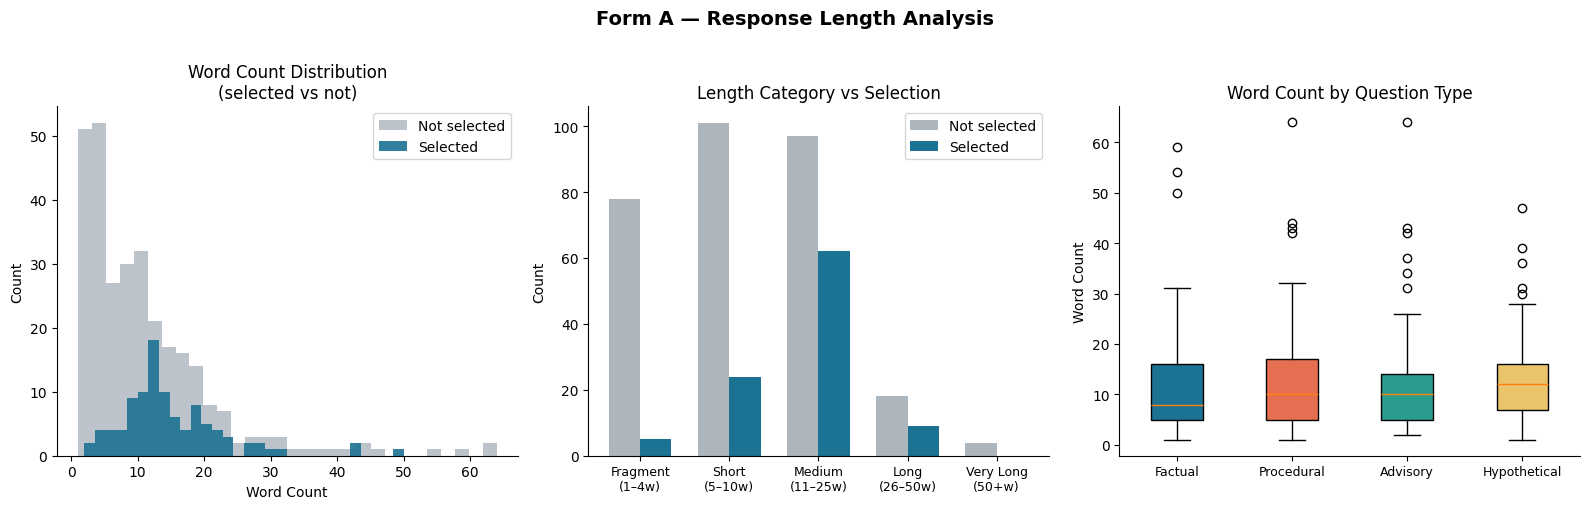


Selection rate by length category:
                   selected  total  rate_%
LengthCat                                 
Fragment\n(1–4w)          5     83     6.0
Short\n(5–10w)           24    125    19.2
Medium\n(11–25w)         62    159    39.0
Long\n(26–50w)            9     27    33.3
Very Long\n(50+w)         0      4     0.0


In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
# CELL 2 — Response length analysis
# ─────────────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle("Form A — Response Length Analysis", fontsize=14, fontweight="bold", y=1.01)

# ── 2a: overall word count histogram, separated selected vs not ──
ax = axes[0]
ax.hist(df[~df["Selected"]]["word_count"], bins=30, color="#ADB5BD", alpha=0.8, label="Not selected")
ax.hist(df[df["Selected"]]["word_count"],  bins=30, color="#1C7293", alpha=0.9, label="Selected")
ax.set_xlabel("Word Count"); ax.set_ylabel("Count")
ax.set_title("Word Count Distribution\n(selected vs not)"); ax.legend()
ax.spines[["top","right"]].set_visible(False)

# ── 2b: length categories grouped bar ──
ax = axes[1]
cat_summary = df.groupby(["LengthCat","Selected"]).size().unstack(fill_value=0)
cat_summary.columns = ["Not Selected","Selected"]
x = np.arange(len(cat_summary))
w = 0.35
ax.bar(x - w/2, cat_summary["Not Selected"], w, color="#ADB5BD", label="Not selected")
ax.bar(x + w/2, cat_summary["Selected"],     w, color="#1C7293", label="Selected")
ax.set_xticks(x); ax.set_xticklabels(cat_summary.index, fontsize=9)
ax.set_title("Length Category vs Selection"); ax.set_ylabel("Count"); ax.legend()
ax.spines[["top","right"]].set_visible(False)

# ── 2c: boxplot by question type ──
ax = axes[2]
type_order = ["FACTUAL","PROCEDURAL","ADVISORY","HYPOTHETICAL"]
data_to_plot = [df[df["Type"]==t]["word_count"].values for t in type_order]
bp = ax.boxplot(data_to_plot, patch_artist=True, notch=False)
for patch, t in zip(bp["boxes"], type_order):
    patch.set_facecolor(TYPE_COLORS[t])
ax.set_xticklabels([t.capitalize() for t in type_order], fontsize=9)
ax.set_ylabel("Word Count"); ax.set_title("Word Count by Question Type")
ax.spines[["top","right"]].set_visible(False)

plt.tight_layout()
plt.savefig("eda_length_distribution.png", dpi=160, bbox_inches="tight")
plt.show()

# Print selection rate by length category
print("\nSelection rate by length category:")
sr = df.groupby("LengthCat")["Selected"].agg(["sum","count"])
sr["rate_%"] = (sr["sum"] / sr["count"] * 100).round(1)
print(sr.rename(columns={"sum":"selected","count":"total"}))

Cell 2 — Response Length Analysis:
The clearest finding is the sweet spot at Medium length (11–25 words) — 39% selection rate, the highest of any category. This makes intuitive sense: medium-length responses are specific enough to be a real question but concise enough to be directly usable.
Fragments (1–4 words) barely made it at 6% — they name a concept but don't form a question. Very Long responses (50+) scored 0% — they tend to be multi-part essays that need heavy decomposition before any single question can be extracted.
The histogram confirms this pattern visually: selected responses (teal) are almost absent below 5 words and cluster between 8–20 words. The grey mass at the far left is the fragment pile — lots of them, almost none selected.
The boxplot on the right shows all 4 question types have nearly identical distributions, which confirms that response length wasn't driven by the scenario — Factual vs Hypothetical didn't make people write more or less. The outliers (circles above 40 words) appear across all types and are mostly the Group C multi-part responses from Cell 1's analysis.

Notebook one-liner:
Sweet spot for selection is 11–25 words (39% rate). Fragments get rejected, very long responses can't be used directly. All 4 scenarios produce similarly-lengthed responses — it's the respondent's engagement style, not the topic, that drives length

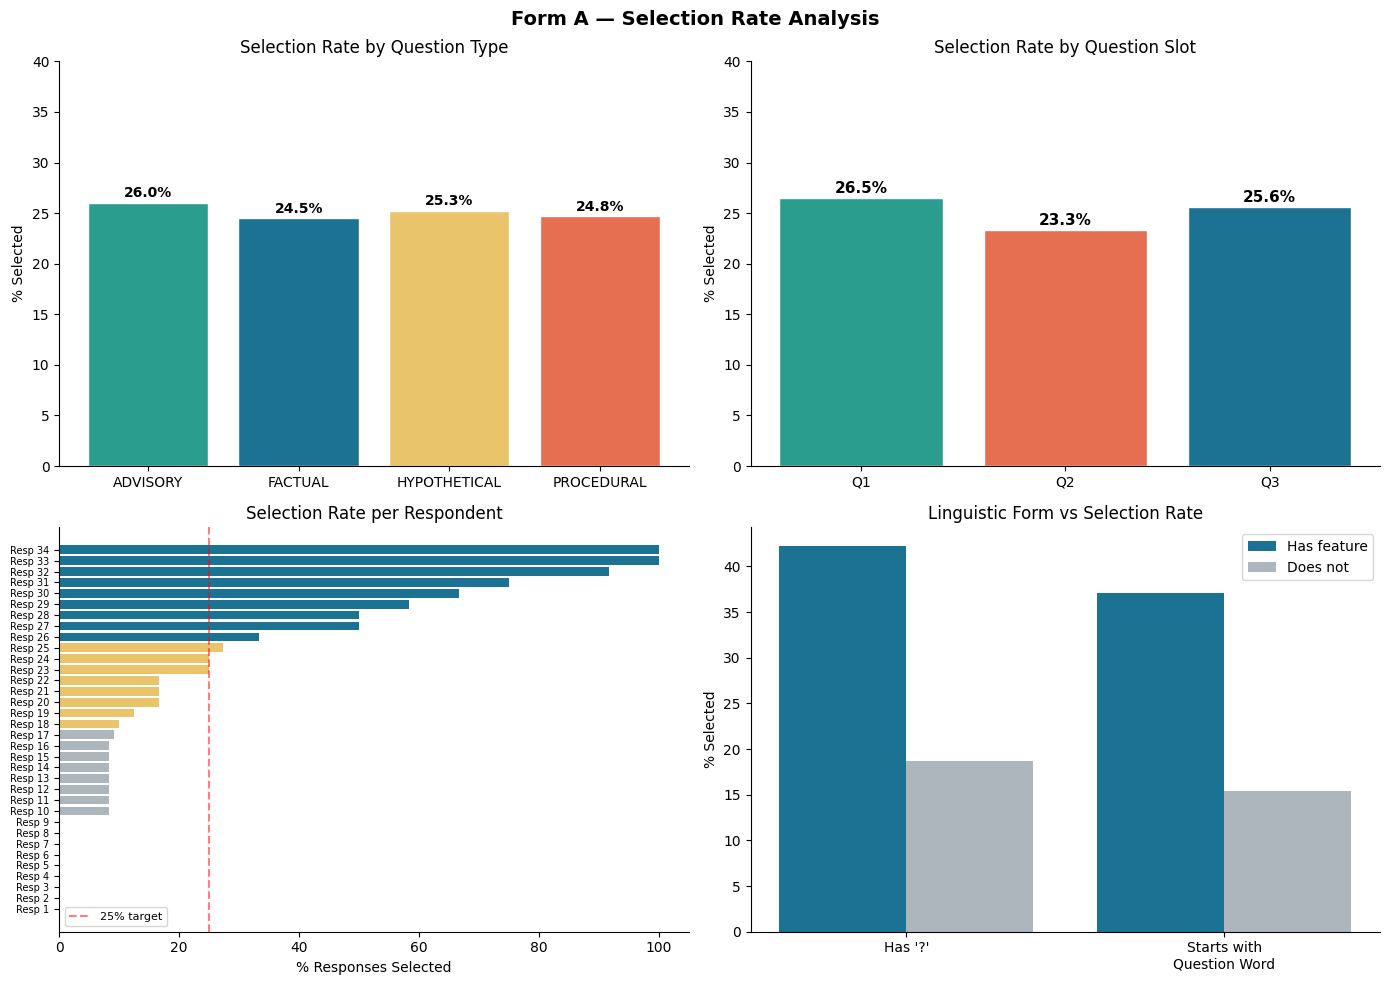

In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
# CELL 3 — What gets selected? Rate by type, slot, length, respondent
# ─────────────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle("Form A — Selection Rate Analysis", fontsize=14, fontweight="bold")

# ── 3a: selection rate by type ──
ax = axes[0,0]
by_type = df.groupby("Type")["Selected"].agg(["sum","count"])
by_type["rate"] = by_type["sum"] / by_type["count"] * 100
bars = ax.bar(by_type.index, by_type["rate"],
              color=[TYPE_COLORS[t] for t in by_type.index], edgecolor="white")
for bar, val in zip(bars, by_type["rate"]):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.5, f"{val:.1f}%",
            ha="center", fontsize=10, fontweight="bold")
ax.set_title("Selection Rate by Question Type"); ax.set_ylabel("% Selected")
ax.set_ylim(0, 40); ax.spines[["top","right"]].set_visible(False)

# ── 3b: selection rate by slot (Q1/Q2/Q3) ──
ax = axes[0,1]
by_slot = df.groupby("SlotNum")["Selected"].agg(["sum","count"])
by_slot["rate"] = by_slot["sum"] / by_slot["count"] * 100
ax.bar(["Q1","Q2","Q3"], by_slot["rate"], color=["#2A9D8F","#E76F51","#1C7293"], edgecolor="white")
for i, val in enumerate(by_slot["rate"]):
    ax.text(i, val+0.5, f"{val:.1f}%", ha="center", fontsize=11, fontweight="bold")
ax.set_title("Selection Rate by Question Slot"); ax.set_ylabel("% Selected")
ax.set_ylim(0, 40); ax.spines[["top","right"]].set_visible(False)

# ── 3c: selection rate per respondent (ordered) ──
ax = axes[1,0]
by_resp = df.groupby("Respondent")["Selected"].agg(["sum","count"])
by_resp["rate"] = by_resp["sum"] / by_resp["count"] * 100
by_resp = by_resp.sort_values("rate", ascending=True)
colors = ["#1C7293" if r >= 33 else "#E9C46A" if r >= 10 else "#ADB5BD" for r in by_resp["rate"]]
ax.barh(range(len(by_resp)), by_resp["rate"], color=colors)
ax.set_yticks(range(len(by_resp)))
ax.set_yticklabels([f"Resp {i+1}" for i in range(len(by_resp))], fontsize=7)
ax.axvline(x=25, color="red", linestyle="--", alpha=0.5, label="25% target")
ax.set_xlabel("% Responses Selected"); ax.set_title("Selection Rate per Respondent")
ax.legend(fontsize=8); ax.spines[["top","right"]].set_visible(False)

# ── 3d: question mark & structure vs selection ──
ax = axes[1,1]
features = ["has_question_mark", "starts_with_q_word"]
labels   = ["Has '?'", "Starts with\nQuestion Word"]
sel_rates = [df[df[f]]["Selected"].mean()*100 for f in features]
not_sel   = [df[~df[f]]["Selected"].mean()*100 for f in features]
x = np.arange(len(features))
ax.bar(x - 0.2, sel_rates, 0.4, color="#1C7293", label="Has feature")
ax.bar(x + 0.2, not_sel,   0.4, color="#ADB5BD", label="Does not")
ax.set_xticks(x); ax.set_xticklabels(labels)
ax.set_ylabel("% Selected"); ax.set_title("Linguistic Form vs Selection Rate")
ax.legend(); ax.spines[["top","right"]].set_visible(False)

plt.tight_layout()
plt.savefig("eda_selection_analysis.png", dpi=160, bbox_inches="tight")
plt.show()

Cell 3 — Selection Rate Analysis:
Four separate stories here.
Top-left (by type): All four types land within 1.5% of each other — Advisory 26%, Factual 24.5%, Hypothetical 25.3%, Procedural 24.8%. This is essentially flat. It means the curation team succeeded in their design goal: equal quality was achievable across all scenario types, and no scenario was inherently "easier" or "harder" to produce good questions for.
Top-right (by slot): Q2 dips slightly to 23.3% while Q1 and Q3 sit at ~26%. Small effect, but Q2 is consistently the "middle" question — respondents had already spent their clearest thought on Q1 and weren't yet summarising as they would in Q3. The effect is minor and not a concern.
Bottom-left (per respondent): This is the most striking chart. The distribution is heavily skewed — Resp 33 and 34 had nearly 100% selection rates, while the bottom ~15 respondents contributed nothing usable (0% selection, all grey). A small group of highly engaged respondents essentially carried the quality of the dataset. This is typical in crowd-sourced data but important to acknowledge — the question bank is not democratically distributed across all 34 respondents.
Bottom-right (linguistic form): The strongest signal in the entire EDA. Responses containing a question mark were selected at 42% vs only 19% without. Responses starting with a question word (What, How, Where etc.) selected at 38% vs 15% without. Both roughly double the selection rate. The lesson: people who thought in question form produced usable stimuli; people who thought in action or note form did not.

Notebook one-liner:
Selection is uniform across types by design, but wildly uneven across respondents — a few engaged contributors carried the dataset. The single strongest predictor of selection is whether the response is grammatically phrased as a question (42% vs 19%).

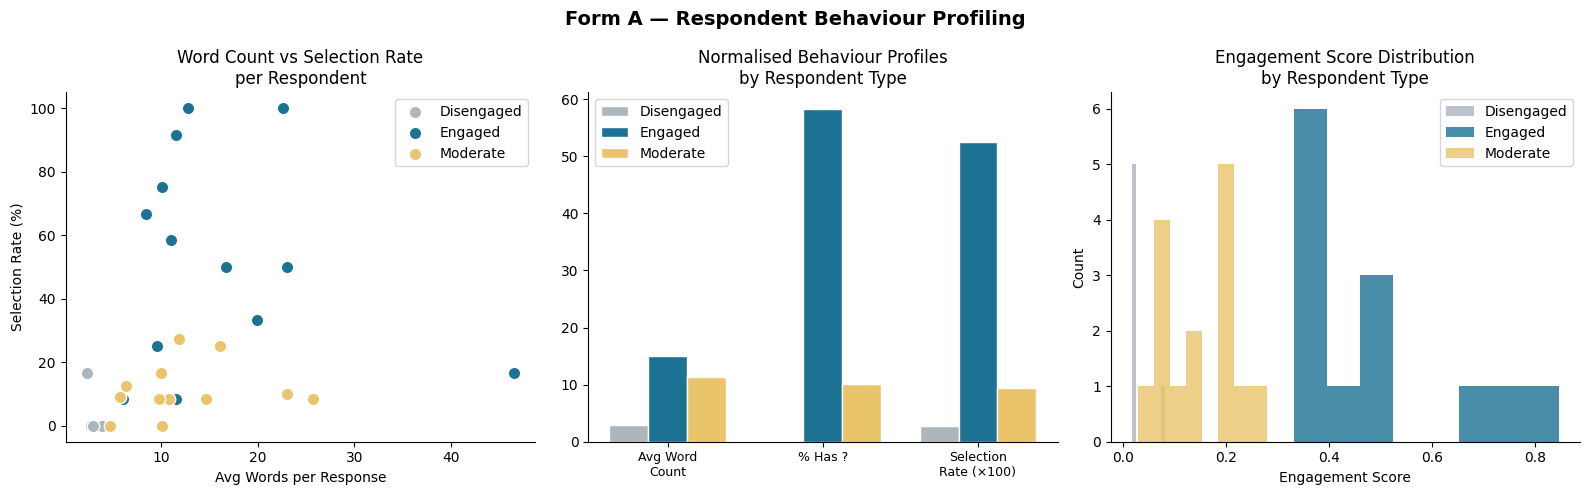

,n_respondents,avg_words,pct_fragments,selection_rate_pct
BehaviourType,,,,
Disengaged,6,3.1,81.9,2.8
Engaged,13,16.1,4.5,52.6
Moderate,15,12.2,10.2,9.5


In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
# CELL 4 — Respondent behaviour: engagement types
# ─────────────────────────────────────────────────────────────────────────────
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

resp_df = df.groupby("Respondent").agg(
    total_responses    = ("RawResponse","count"),
    avg_word_count     = ("word_count","mean"),
    max_word_count     = ("word_count","max"),
    pct_fragments      = ("word_count", lambda x: (x <= 4).mean() * 100),
    pct_question_mark  = ("has_question_mark","mean"),
    pct_q_word_start   = ("starts_with_q_word","mean"),
    n_selected         = ("Selected","sum"),
    selection_rate     = ("Selected","mean"),
).reset_index()

resp_df["engagement_score"] = (
    resp_df["avg_word_count"] / resp_df["avg_word_count"].max() * 0.3 +
    resp_df["pct_question_mark"] * 0.3 +
    resp_df["selection_rate"] * 0.4
)

# K-Means clustering into 3 respondent types
feats = ["avg_word_count","pct_fragments","pct_question_mark","selection_rate"]
X = StandardScaler().fit_transform(resp_df[feats].fillna(0))
km = KMeans(n_clusters=3, random_state=42, n_init=20)
resp_df["cluster"] = km.fit_predict(X)

# Label clusters by engagement
cluster_eng = resp_df.groupby("cluster")["engagement_score"].mean().sort_values()
label_map = {cluster_eng.index[0]: "Disengaged", cluster_eng.index[1]: "Moderate", cluster_eng.index[2]: "Engaged"}
resp_df["BehaviourType"] = resp_df["cluster"].map(label_map)

BCOLORS = {"Disengaged":"#ADB5BD", "Moderate":"#E9C46A", "Engaged":"#1C7293"}

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle("Form A — Respondent Behaviour Profiling", fontsize=14, fontweight="bold")

# ── 4a: scatter avg word count vs selection rate ──
ax = axes[0]
for btype, grp in resp_df.groupby("BehaviourType"):
    ax.scatter(grp["avg_word_count"], grp["selection_rate"]*100,
               color=BCOLORS[btype], label=btype, s=80, edgecolors="white", zorder=3)
ax.set_xlabel("Avg Words per Response"); ax.set_ylabel("Selection Rate (%)")
ax.set_title("Word Count vs Selection Rate\nper Respondent"); ax.legend()
ax.spines[["top","right"]].set_visible(False)

# ── 4b: cluster profile radar-style bar ──
ax = axes[1]
metrics = ["avg_word_count","pct_question_mark","selection_rate"]
labels  = ["Avg Word\nCount","% Has ?","Selection\nRate (×100)"]
cluster_means = resp_df.groupby("BehaviourType")[metrics].mean()
cluster_means["selection_rate"] *= 100
x = np.arange(len(metrics))
w = 0.25
for i, (btype, row) in enumerate(cluster_means.iterrows()):
    vals = [row["avg_word_count"] / cluster_means["avg_word_count"].max() * 15,
            row["pct_question_mark"] * 100,
            row["selection_rate"]]
    ax.bar(x + (i-1)*w, vals, w, color=BCOLORS[btype], label=btype, edgecolor="white")
ax.set_xticks(x); ax.set_xticklabels(labels, fontsize=9)
ax.set_title("Normalised Behaviour Profiles\nby Respondent Type"); ax.legend()
ax.spines[["top","right"]].set_visible(False)

# ── 4c: engagement score distribution ──
ax = axes[2]
for btype, grp in resp_df.groupby("BehaviourType"):
    ax.hist(grp["engagement_score"], bins=8, color=BCOLORS[btype], alpha=0.8, label=btype)
ax.set_xlabel("Engagement Score"); ax.set_ylabel("Count")
ax.set_title("Engagement Score Distribution\nby Respondent Type"); ax.legend()
ax.spines[["top","right"]].set_visible(False)

plt.tight_layout()
plt.savefig("eda_respondent_behaviour.png", dpi=160, bbox_inches="tight")
plt.show()

# Summary table
display(resp_df.groupby("BehaviourType").agg(
    n_respondents=("Respondent","count"),
    avg_words=("avg_word_count","mean"),
    pct_fragments=("pct_fragments","mean"),
    selection_rate_pct=("selection_rate", lambda x: (x.mean()*100).round(1)),
).round(1))

Cell 4 — Respondent Behaviour Profiling:
The K-Means clustering split 34 respondents into three behavioural types, and the table makes the contrast stark.
Disengaged (6 respondents): Average 3.1 words per response, 81.9% of their submissions are fragments. Selection rate 2.8% — practically zero. These are the "car", "Hospitals", "Swimming" respondents from the raw data. They participated but didn't cognitively engage with the disaster scenario as a question-generation task.
Engaged (13 respondents): Average 16.1 words, only 4.5% fragments, selection rate 52.6%. More than half of everything they submitted made it into the final bank. These 13 people — 38% of participants — are essentially the authors of the question bank.
Moderate (15 respondents): The largest group. Average 12.2 words, 10.2% fragments, 9.5% selection rate. They tried, wrote reasonable-length responses, but most didn't meet the clarity or type-assignability threshold. They contributed the "background noise" of the dataset.
The scatter plot on the left tells the same story visually — Engaged (blue) clusters in the upper-middle zone of 10–25 words with high selection rates. Notice the one Engaged outlier at ~47 words but only 17% selection — that's a Group C respondent who wrote very detailed multi-part essays that couldn't be used without heavy decomposition. Word count alone doesn't guarantee selection; question form does, which the middle chart confirms: Engaged respondents dominate the "% Has ?" bar by a huge margin.
The right histogram shows Engaged scores are tightly grouped around 0.35–0.45 with a long tail to 0.85 — consistently high, no stragglers. Moderate spreads widely, which makes sense: some in this group had one or two very good questions buried among weak ones.

Notebook one-liner:
13 engaged respondents (38% of participants) wrote 52.6% of what was usable — they are the real authors of the question bank. The defining trait of engagement is not length but question form: using a question mark and question-word structure.

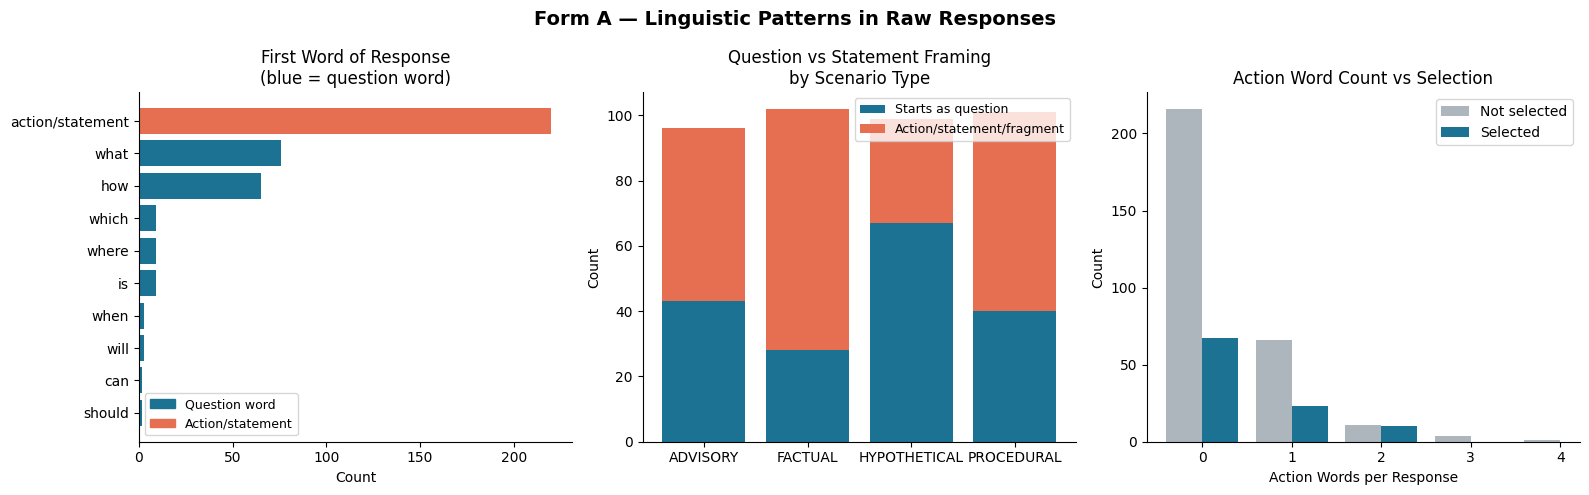


Top-10 content words by question type:
  FACTUAL: typhoon, safe, evacuation, can, shelter, emergency, storm, place, food, need
  PROCEDURAL: water, safe, know, higher, get, ground, emergency, should, want, where
  ADVISORY: water, daily, use, can, activities, cooking, reuse, want, would, without
  HYPOTHETICAL: earthquake, water, family, building, safe, can, happens, home, buildings, city


In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
# CELL 5 — How people phrase disaster questions
# ─────────────────────────────────────────────────────────────────────────────
from collections import Counter
import re

Q_STARTERS = ["what","how","where","when","why","who","which","is","are","can","should","will","do","does"]
ACTION_WORDS = ["go","take","find","check","get","prepare","evacuate","call","look","move","stay","need","search"]

def get_starter(text):
    first = text.strip().lower().split()[0] if text.strip() else "other"
    return first if first in Q_STARTERS else "action/statement"

df["starter"] = df["RawResponse"].apply(get_starter)

# Count action words
def count_action(text):
    words = re.findall(r'\b\w+\b', text.lower())
    return sum(1 for w in words if w in ACTION_WORDS)

df["action_word_count"] = df["RawResponse"].apply(count_action)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle("Form A — Linguistic Patterns in Raw Responses", fontsize=14, fontweight="bold")

# ── 5a: starter word distribution ──
ax = axes[0]
starter_counts = df["starter"].value_counts().head(10)
colors = ["#1C7293" if s in Q_STARTERS else "#E76F51" for s in starter_counts.index]
ax.barh(starter_counts.index[::-1], starter_counts.values[::-1], color=colors[::-1])
ax.set_xlabel("Count"); ax.set_title("First Word of Response\n(blue = question word)")
ax.spines[["top","right"]].set_visible(False)
q_patch = mpatches.Patch(color="#1C7293", label="Question word")
a_patch = mpatches.Patch(color="#E76F51", label="Action/statement")
ax.legend(handles=[q_patch, a_patch], fontsize=9)

# ── 5b: starter by type — stacked bar (q-word vs not) ──
ax = axes[1]
starter_by_type = df.groupby("Type")["starts_with_q_word"].agg(["sum","count"])
starter_by_type["not_q"] = starter_by_type["count"] - starter_by_type["sum"]
ax.bar(starter_by_type.index, starter_by_type["sum"],  color="#1C7293", label="Starts as question")
ax.bar(starter_by_type.index, starter_by_type["not_q"], bottom=starter_by_type["sum"],
       color="#E76F51", label="Action/statement/fragment")
ax.set_ylabel("Count"); ax.set_title("Question vs Statement Framing\nby Scenario Type")
ax.legend(fontsize=9); ax.spines[["top","right"]].set_visible(False)

# ── 5c: action words in selected vs not ──
ax = axes[2]
sel_action   = df[df["Selected"]]["action_word_count"].value_counts().sort_index()
unsel_action = df[~df["Selected"]]["action_word_count"].value_counts().sort_index()
ax.bar(unsel_action.index - 0.2, unsel_action.values, 0.4, color="#ADB5BD", label="Not selected")
ax.bar(sel_action.index   + 0.2, sel_action.values,   0.4, color="#1C7293", label="Selected")
ax.set_xlabel("Action Words per Response"); ax.set_ylabel("Count")
ax.set_title("Action Word Count vs Selection"); ax.legend()
ax.spines[["top","right"]].set_visible(False)

plt.tight_layout()
plt.savefig("eda_linguistic_patterns.png", dpi=160, bbox_inches="tight")
plt.show()

# Most common words per type
print("\nTop-10 content words by question type:")
import re
STOPWORDS = {"the","a","an","i","to","of","and","in","is","it","my","for","that","if","you",
             "will","be","with","at","or","on","are","not","we","me","this","do","from","have","what","how"}
for t in ["FACTUAL","PROCEDURAL","ADVISORY","HYPOTHETICAL"]:
    words = re.findall(r'\b[a-z]{3,}\b', ' '.join(df[df["Type"]==t]["RawResponse"]).lower())
    top = [w for w,_ in Counter(words).most_common(25) if w not in STOPWORDS][:10]
    print(f"  {t}: {', '.join(top)}")

Cell 5 — Linguistic Patterns:
Left chart — First word: The orange "action/statement" bar at ~ 220 dwarfs everything else combined. Most participants did not think in question form at all — they brainstormed actions ("Go to tallest building", "Take oxygen bottles") or named topics ("Evacuation routes", "Shelter capacity"). "What" and "How" are the top question starters at ~ 70 each, then the remaining question words trail off quickly. The dominant mode of public disaster thinking is action-oriented, not inquiry-oriented. That's the core behavioural finding of this entire EDA.
Middle chart — Question vs Statement by scenario: The most surprising result here. Hypothetical has the highest proportion of question-form responses (roughly 68%), followed by Procedural (~ 40%) and Advisory (~ 45%). Factual has the least — around 27%. This is counterintuitive: you'd expect factual thinking to produce "What is X?" questions most naturally. Instead, it produced statements and noun-fragments ("Storm surge depth", "Evacuation maps"). The reason is likely that when people think about concrete facts, they name the fact rather than formulate the question — hypothetical thinking, by contrast, almost forces "What if...?" framing.
Right chart — Action words vs selection: No meaningful signal. Whether a response contained 0, 1, or 2 action words made no consistent difference to selection — the selected (teal) bar tracks proportionally with the not-selected (grey) at every count. This confirms that action content doesn't help or hurt; what matters is grammatical question form.
Content words — the semantic fingerprints: Each scenario produced a perfectly distinct vocabulary cluster. FACTUAL centres on typhoon/evacuation/shelter — infrastructure and escape. PROCEDURAL centres on water/higher/ground — immediate physical actions during flooding. ADVISORY is almost entirely water conservation vocabulary (daily/use/cooking/reuse) because Cape Town Day Zero is specifically about rationing. HYPOTHETICAL centres on earthquake/family/building — contingency and structural risk thinking. This confirms the four scenarios genuinely induced four different cognitive frames, which is exactly what you need for a diverse question bank.

Notebook one-liner:
Most participants think in action form, not question form — "go to high ground" not "where should I go?". Hypothetical scenarios produce the most question-like thinking. Each scenario left a clean semantic fingerprint in vocabulary, confirming cognitive diversity across the question bank.

GPU: Tesla T4


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

... (4 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/4 [00:00<?, ?it/s]

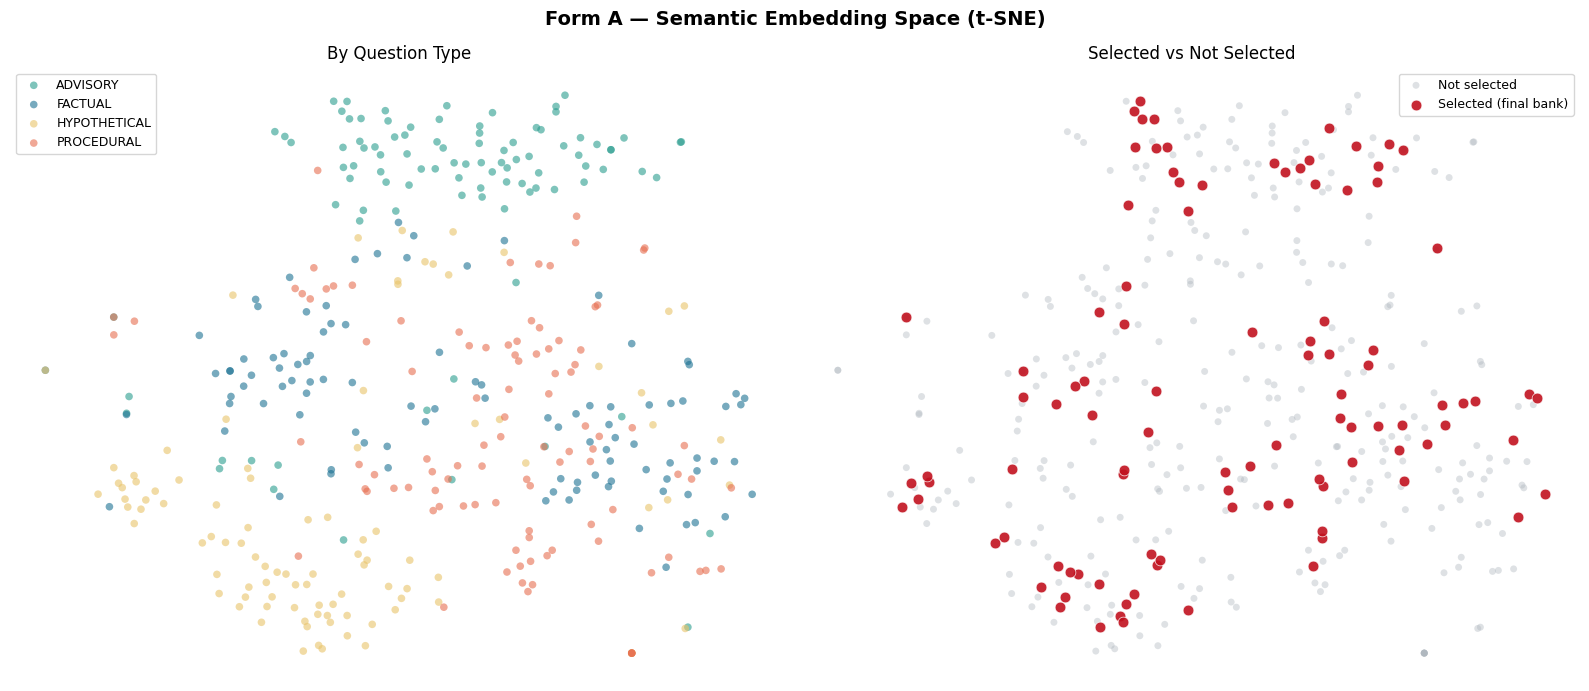


✅ Embeddings shape: (398, 384)


In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
# CELL 6 — Semantic embeddings (T4 GPU) + t-SNE visualisation
# ─────────────────────────────────────────────────────────────────────────────
!pip install -q sentence-transformers umap-learn

from sentence_transformers import SentenceTransformer
from sklearn.manifold import TSNE
import torch

print(f"GPU: {torch.cuda.get_device_name(0)}")

model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2", device="cuda")
texts = df["RawResponse"].tolist()
embeddings = model.encode(texts, batch_size=128, show_progress_bar=True,
                           normalize_embeddings=True)

# t-SNE to 2D
tsne = TSNE(n_components=2, random_state=42, perplexity=30, n_iter=1000)
coords = tsne.fit_transform(embeddings)
df["tsne_x"] = coords[:, 0]
df["tsne_y"] = coords[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
fig.suptitle("Form A — Semantic Embedding Space (t-SNE)", fontsize=14, fontweight="bold")

# ── 6a: colour by question type ──
ax = axes[0]
for t, grp in df.groupby("Type"):
    ax.scatter(grp["tsne_x"], grp["tsne_y"], c=TYPE_COLORS[t],
               label=t, alpha=0.6, s=30, edgecolors="none")
ax.set_title("By Question Type"); ax.legend(fontsize=9)
ax.axis("off")

# ── 6b: colour by selection ──
ax = axes[1]
ax.scatter(df[~df["Selected"]]["tsne_x"], df[~df["Selected"]]["tsne_y"],
           c="#ADB5BD", alpha=0.4, s=25, label="Not selected", edgecolors="none")
ax.scatter(df[df["Selected"]]["tsne_x"], df[df["Selected"]]["tsne_y"],
           c="#C1121F", alpha=0.9, s=60, label="Selected (final bank)", edgecolors="white", linewidths=0.5)
ax.set_title("Selected vs Not Selected"); ax.legend(fontsize=9)
ax.axis("off")

plt.tight_layout()
plt.savefig("eda_tsne_embeddings.png", dpi=160, bbox_inches="tight")
plt.show()

print(f"\n✅ Embeddings shape: {embeddings.shape}")

# Save embeddings for next cell
import numpy as np
np.save("forma_embeddings.npy", embeddings)

Cell 6 — Semantic Embedding Space (t-SNE):
Left plot — By question type: The four types do NOT form clean, isolated clusters — they overlap significantly in the middle, with only partial separation. The clearest separation is Hypothetical (yellow) which pulls toward the bottom-left corner, and Advisory (teal) which forms a loose cloud in the upper region. Factual (blue) and Procedural (salmon/pink) are heavily interleaved in the centre.
This is actually the correct result for this dataset. The four scenarios cover different disasters, but the underlying human concerns — where to go, what to take, how to stay safe — are shared across all types. A factual question about storm shelter location and a procedural question about evacuating during a flood live in the same semantic neighbourhood because they're both about survival and escape. The separation that does exist (Advisory top, Hypothetical bottom-left) reflects scenario vocabulary: Cape Town water rationing is genuinely a different topic from seismic risk.
Right plot — Selected vs not selected: The red dots (selected) are scattered throughout the entire space — there is no "selection zone." Selected questions appear in every corner, every cluster region, not concentrated in one spot. This is the key quality signal: the curation team successfully sampled diverse semantic coverage. If all red dots were bunched together, it would mean the question bank was semantically narrow. Instead, selection spread across the full space means the 100 final questions genuinely cover the semantic breadth of what 34 people thought about across all four disaster scenarios.
The few grey dots that are completely isolated at the edges (far left, far bottom) are likely the extreme fragments — single-word responses so short they embedded far from the main discourse.
Embeddings shape (398, 384): Each response is a 384-dimensional vector from MiniLM-L6-v2, compressed to 2D by t-SNE purely for visualisation. The actual pairwise similarity computations in your pipeline use the full 384 dimensions — this plot is only for human interpretation.

Notebook one-liner:
The four question types overlap semantically because disaster survival concerns are shared across scenarios. Selected questions (red) are distributed across the entire space — confirming the final bank has broad semantic coverage, not a narrow cluster of similar items.

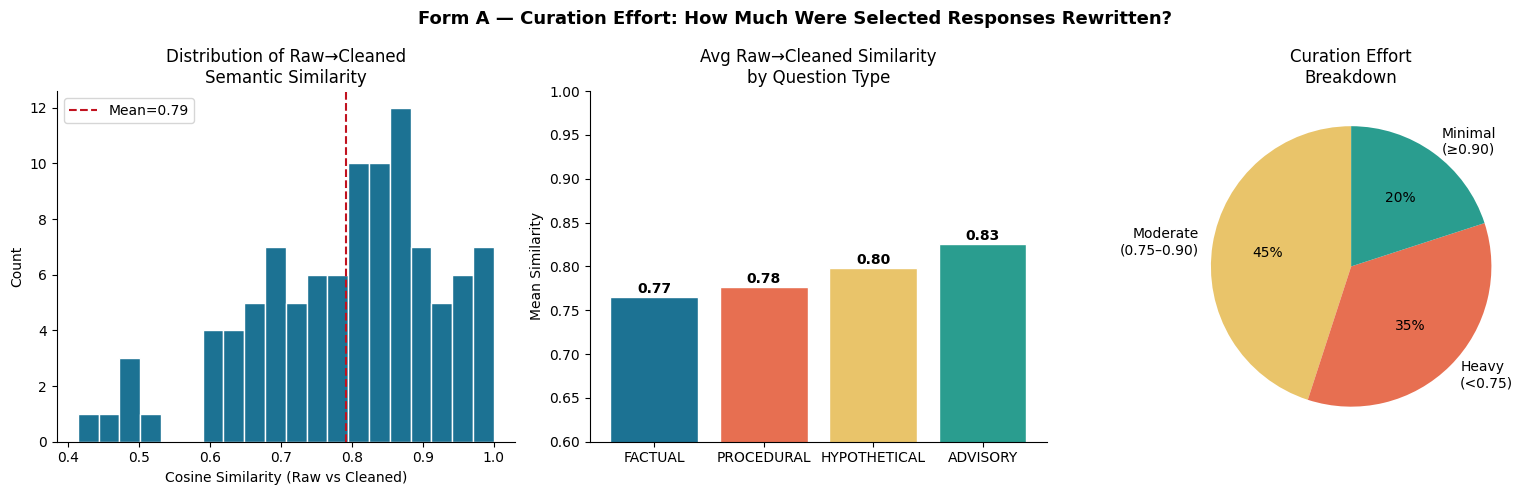


Top 5 most-rewritten responses (lowest similarity):
  [FACTUAL] Sim=0.41
    RAW:     How likely it is to hot my place ?
    CLEANED: How likely is the typhoon to make a direct hit on my specific location?

  [HYPOTHETICAL] Sim=0.45
    RAW:     What if I am at work or away from my family? (I need a plan to safely reconnect 
    CLEANED: What if I am at work and completely separated from my family when the earthquake

  [FACTUAL] Sim=0.49
    RAW:     Is our home in a red zone
    CLEANED: Is my home in a high-risk evacuation zone for this typhoon?

  [ADVISORY] Sim=0.49
    RAW:     Methods to hold out if the crisis will prolong, possibilities of leaving town.
    CLEANED: What should I plan for if the water crisis extends beyond the announced three-mo

  [PROCEDURAL] Sim=0.50
    RAW:     Keep a high-decibel whistle or a bright flashlight/strobe nearby. In the dark, s
    CLEANED: What is the most effective way to signal rescuers from a rooftop when I cannot u



In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
# CELL 7 — How much did curators rewrite selected responses?
# ─────────────────────────────────────────────────────────────────────────────
from sklearn.metrics.pairwise import cosine_similarity

selected_df = df[df["Selected"] & df["CleanedQuestion"].notna()].copy()
raw_texts     = selected_df["RawResponse"].tolist()
cleaned_texts = selected_df["CleanedQuestion"].astype(str).tolist()

raw_embs     = model.encode(raw_texts,     normalize_embeddings=True)
cleaned_embs = model.encode(cleaned_texts, normalize_embeddings=True)

sims = [float(cosine_similarity(r.reshape(1,-1), c.reshape(1,-1))[0,0])
        for r, c in zip(raw_embs, cleaned_embs)]
selected_df["raw_clean_similarity"] = sims

# Curation effort labels
def effort_label(s):
    if s >= 0.90: return "Minimal\n(≥0.90)"
    elif s >= 0.75: return "Moderate\n(0.75–0.90)"
    else: return "Heavy\n(<0.75)"
selected_df["curation_effort"] = selected_df["raw_clean_similarity"].apply(effort_label)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle("Form A — Curation Effort: How Much Were Selected Responses Rewritten?",
             fontsize=13, fontweight="bold")

# ── 7a: similarity histogram ──
ax = axes[0]
ax.hist(sims, bins=20, color="#1C7293", edgecolor="white")
ax.axvline(np.mean(sims), color="#C1121F", linestyle="--", label=f"Mean={np.mean(sims):.2f}")
ax.set_xlabel("Cosine Similarity (Raw vs Cleaned)")
ax.set_ylabel("Count"); ax.set_title("Distribution of Raw→Cleaned\nSemantic Similarity")
ax.legend(); ax.spines[["top","right"]].set_visible(False)

# ── 7b: by question type ──
ax = axes[1]
by_type_sim = selected_df.groupby("Type")["raw_clean_similarity"].mean().sort_values()
colors = [TYPE_COLORS[t] for t in by_type_sim.index]
bars = ax.bar(by_type_sim.index, by_type_sim.values, color=colors, edgecolor="white")
for bar, val in zip(bars, by_type_sim.values):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.005, f"{val:.2f}",
            ha="center", fontsize=10, fontweight="bold")
ax.set_ylim(0.6, 1.0); ax.set_ylabel("Mean Similarity")
ax.set_title("Avg Raw→Cleaned Similarity\nby Question Type")
ax.spines[["top","right"]].set_visible(False)

# ── 7c: effort breakdown pie ──
ax = axes[2]
effort_counts = selected_df["curation_effort"].value_counts()
effort_colors = {"Minimal\n(≥0.90)":"#2A9D8F", "Moderate\n(0.75–0.90)":"#E9C46A", "Heavy\n(<0.75)":"#E76F51"}
ax.pie(effort_counts.values, labels=effort_counts.index,
       colors=[effort_colors.get(l,"#888") for l in effort_counts.index],
       autopct="%1.0f%%", startangle=90,
       textprops={"fontsize":10})
ax.set_title("Curation Effort\nBreakdown")

plt.tight_layout()
plt.savefig("eda_curation_effort.png", dpi=160, bbox_inches="tight")
plt.show()

print("\nTop 5 most-rewritten responses (lowest similarity):")
low = selected_df.nsmallest(5, "raw_clean_similarity")[["Type","RawResponse","CleanedQuestion","raw_clean_similarity"]]
for _, row in low.iterrows():
    print(f"  [{row['Type']}] Sim={row['raw_clean_similarity']:.2f}")
    print(f"    RAW:     {row['RawResponse'][:80]}")
    print(f"    CLEANED: {row['CleanedQuestion'][:80]}")
    print()

Cell 7 — Curation Effort Analysis:Cell 7 — Curation Effort Analysis:
Left histogram — similarity distribution: The mean raw→cleaned similarity is 0.79, and the distribution peaks between 0.80–0.90 with a long left tail down to 0.40. It's slightly left-skewed — most selected responses needed moderate rewrites, but a meaningful minority needed heavy reconstruction. No response scored 1.0, which means every single selected item was rewritten to at least some degree. The curation process was never just copy-paste.
Middle bar — by question type: Advisory required the least rewriting (0.83) — Cape Town water rationing questions tended to be clearly phrased already, probably because the scenario is familiar and domestic. Factual required the most (0.77) — factual thinking produced the most fragments and noun-phrases that needed converting into full questions. Hypothetical sits in the middle (0.80), Procedural just behind (0.78).
Right pie — effort breakdown: Only 20% of selected responses were used with minimal rewriting (similarity ≥ 0.90). The majority — 45% — required moderate rewriting, and 35% required heavy reconstruction (similarity below 0.75). So 80% of the question bank involved meaningful editorial work. This is an important transparency point for your thesis: the final 100 questions are not verbatim participant submissions, they are curator-refined versions that preserve the participant's intent while meeting the clarity and type-assignability criteria.
The 5 most-rewritten examples tell the real story:
The first one is perfect — "How likely it is to hot my place?" (0.41 similarity) became "How likely is the typhoon to make a direct hit on my specific location?" The intent is identical but the original had a typo, vague phrasing, and no domain specificity. The last example is the most dramatic transformation: a participant wrote a procedural tip about carrying a whistle, and the curator extracted the embedded question — "What is the most effective way to signal rescuers from a rooftop when I cannot use my phone?" The raw response wasn't even a question at all.

Notebook one-liner:
Mean curation similarity is 0.79 — 80% of selected responses needed meaningful rewriting. Advisory questions needed least editing, Factual the most. The 5 most-rewritten examples show the curator's role: preserving participant intent while converting fragments, typos, and embedded tips into clean, evaluable questions.